In [1]:
import numpy as np
import random
import pandas as pd
from tqdm import tqdm
import os
import matplotlib.pyplot as plt
from pathlib import Path

# Set professional style for all plots
plt.style.use('seaborn-v0_8')  # Use a clean style
plt.rcParams.update({
    'font.size': 12,
    'font.family': 'sans-serif',
    'axes.labelsize': 14,
    'axes.titlesize': 16,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
    'figure.titlesize': 18,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

# Define consistent color palettes
colors_age = ['#1f77b4', '#ff7f0e', '#2ca02c']  # Blue, Orange, Green for 0-19, 20-64, 65+
colors_tfr = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']  # Blue, Orange, Green, Red for TFRs
colors_change = ['#d62728', '#2ca02c']  # Red for decrease, Green for increase


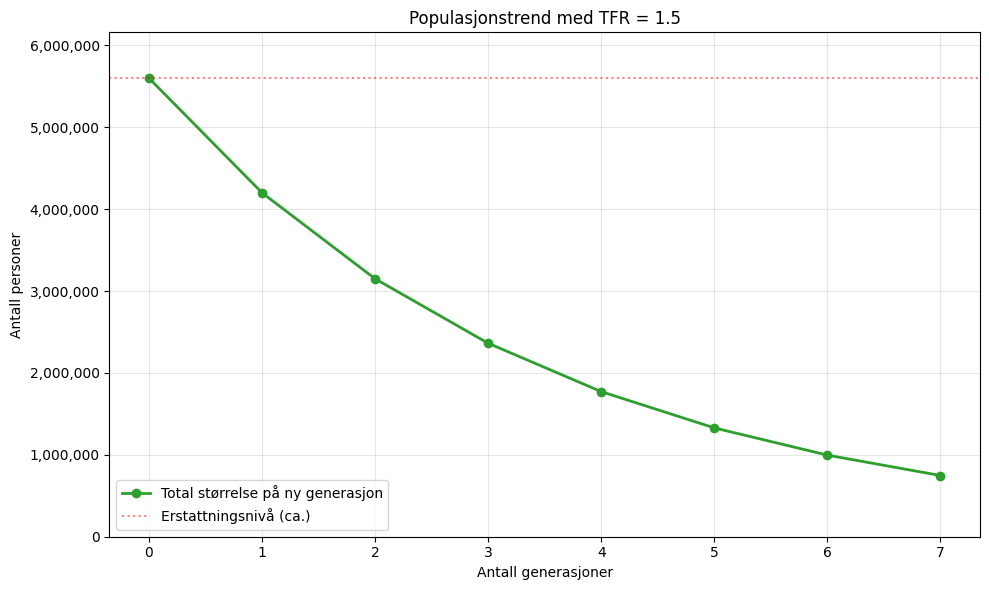

Oppsummering (TFR = 1.5):
Startkohort: 5,600,000
Siste kohort (Gen 7): 747,509


In [8]:
import matplotlib.pyplot as plt

# Parametere
tfr = 1.5  # Sett dette til 2.1 for stabilitet, > 2.1 for vekst, < 2.1 for nedgang
initial_women = 2.8e6
generations = 7
female_ratio = 0.5  # % av fødsler som er jenter

# Vi skal spore størrelsen til hver NY generasjon
generation_sizes = [initial_women / female_ratio] # Total størrelse på startgenerasjonen
women_in_generation = [initial_women]

for gen in range(1, generations + 1):
    # 1. Totalt antall barn født av den nåværende generasjonen av kvinner
    total_children = women_in_generation[-1] * tfr
    
    # 2. Av disse barna, hvor mange er jenter?
    new_women = total_children * female_ratio
    
    generation_sizes.append(total_children)
    women_in_generation.append(new_women)

# Opprett visualisering
fig, ax = plt.subplots(figsize=(10, 6))
years = list(range(generations + 1))

ax.plot(years, generation_sizes, marker='o', linewidth=2, label='Total størrelse på ny generasjon', color='#2ca02c')
# ax.plot(years, women_in_generation, marker='s', linewidth=2, linestyle='--', label='Kvinner i ny generasjon', color='#1f77b4')

# Legg til en horisontal linje ved startpunktet for referanse
ax.axhline(y=generation_sizes[0], color='red', linestyle=':', alpha=0.5, label='Erstattningsnivå (ca.)')

ax.set_xlabel('Antall generasjoner')
ax.set_ylabel('Antall personer')
ax.set_title(f'Populasjonstrend med TFR = {tfr}')
ax.legend()
ax.grid(True, alpha=0.3)

# Formater Y-aksen til å vise komma
ax.get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, p: format(int(x), ',')))
ax.get_xaxis().set_major_locator(plt.MaxNLocator(integer=True))  # Vis kun heltall på X-aksen
ax.set_ylim(0, max(generation_sizes) * 1.1)  # Sett Y-aksen litt høyere enn maksimum for bedre visning

plt.tight_layout()
plt.show()

print(f"Oppsummering (TFR = {tfr}):")
print(f"Startkohort: {int(generation_sizes[0]):,}")
print(f"Siste kohort (Gen {generations}): {int(generation_sizes[-1]):,}")